In [1]:
import torch, subprocess
print("torch:", torch.__version__, "| cuda:", torch.cuda.is_available())
print(subprocess.run("nvidia-smi", shell=True, capture_output=True, text=True).stdout or "GPU nahi mila")

torch: 2.14.1+cu130 | cuda: True
Mon Nov  9 08:51:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------

In [2]:
import os, re, json, math, random, time
import numpy as np, pandas as pd, torch
from PIL import Image, ImageFilter, ImageDraw
from tqdm.auto import tqdm

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = '/content/drive/MyDrive/mllm_grounding_uncertainty'
else:
    SAVE_DIR = '/content/mllm_grounding_uncertainty'
os.makedirs(SAVE_DIR, exist_ok=True)

assert torch.cuda.is_available(), "GPU connect nahi hai: Runtime > Change runtime type > T4 GPU"

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
try:
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_ID, dtype=torch.float16, device_map="cuda", attn_implementation="sdpa").eval()
except TypeError:
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_ID, torch_dtype=torch.float16, device_map="cuda", attn_implementation="sdpa").eval()
processor = AutoProcessor.from_pretrained(MODEL_ID, min_pixels=256*28*28, max_pixels=1280*28*28)
tok = processor.tokenizer
print(torch.cuda.get_device_name(0))

Mounted at /content/drive


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tesla T4


In [3]:
def _clean_logits(module, args, out):
    return torch.nan_to_num(out, nan=0.0, posinf=60000.0, neginf=-60000.0)

model.lm_head.register_forward_hook(_clean_logits)
print("hook lag gaya")

hook lag gaya


README.md:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

  0%|          | 0/400 [00:00<?, ?it/s]

dev 100 test 150


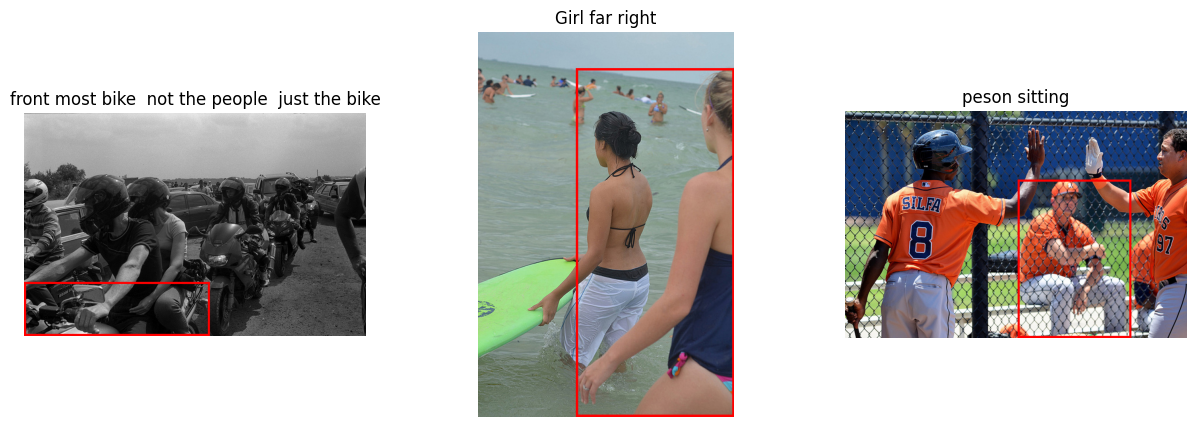

In [4]:
from datasets import load_dataset
import matplotlib.pyplot as plt

DATASET, SPLIT = "lmms-lab/RefCOCO", "val"
DEV_N, TEST_N = 100, 150
BOX_FORMAT = "xywh"   # sanity plot galat dikhe to "xyxy" karein

def fetch(n_total, seed=0, buf=1000):
    ds = load_dataset(DATASET, split=SPLIT, streaming=True).shuffle(seed=seed, buffer_size=buf)
    out = []
    for ex in tqdm(ds, total=n_total):
        out.append(ex)
        if len(out) >= n_total: break
    return out

raw = fetch(int((DEV_N + TEST_N) * 1.6))

def get_expr(ex):
    a = ex.get("answer")
    if isinstance(a, (list, tuple)) and len(a) > 0: return str(a[0]).strip()
    if isinstance(a, str): return a.strip()
    raise KeyError("expression field nahi mila")

def get_box(ex):
    x, y, a, b = [float(v) for v in ex["bbox"]]
    return [x, y, x + a, y + b] if BOX_FORMAT == "xywh" else [x, y, a, b]

items = [dict(img=ex["image"].convert("RGB"), expr=get_expr(ex), box=get_box(ex),
              fid=str(ex.get("file_name", j))) for j, ex in enumerate(raw)]

fids = sorted(set(d["fid"] for d in items)); random.Random(0).shuffle(fids)
dev_f = set(fids[: len(fids) * 3 // 10])
dev  = [d for d in items if d["fid"] in dev_f][:DEV_N]
test = [d for d in items if d["fid"] not in dev_f][:TEST_N]
print("dev", len(dev), "test", len(test))

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, d in zip(axs, test[:3]):
    im = d["img"].copy(); ImageDraw.Draw(im).rectangle(d["box"], outline=(255, 0, 0), width=4)
    ax.imshow(im); ax.set_title(d["expr"]); ax.axis("off")
plt.show()

In [5]:
NUM = r"-?\d+(?:\.\d+)?"
def parse_box(txt):
    pats = [r'"bbox_2d"\s*:\s*\[\s*(%s)\s*,\s*(%s)\s*,\s*(%s)\s*,\s*(%s)\s*\]' % ((NUM,)*4),
            r'\[\s*(%s)\s*,\s*(%s)\s*,\s*(%s)\s*,\s*(%s)\s*\]' % ((NUM,)*4)]
    for p in pats:
        m = re.search(p, txt)
        if m:
            b = [float(m.group(i)) for i in range(1, 5)]
            if b[2] > b[0] and b[3] > b[1]: return b
    return None

def iou(a, b):
    if a is None or b is None: return 0.0
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return float(inter / u) if u > 0 else 0.0

def build_inputs(img, text):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return processor(text=[prompt], images=[img], return_tensors="pt").to("cuda", torch.float16)

def gprompt(expr):
    return f'Locate the object described as "{expr}" in the image and output its bbox coordinates in JSON format.'

GEN_COMMON = dict(max_new_tokens=80, repetition_penalty=1.0)

def to_img_coords(b, inp, img):
    _, gh, gw = inp["image_grid_thw"][0].tolist()
    sx, sy = img.width / (gw * 14), img.height / (gh * 14)
    x1, x2 = np.clip([b[0]*sx, b[2]*sx], 0, img.width); y1, y2 = np.clip([b[1]*sy, b[3]*sy], 0, img.height)
    if x2 - x1 < 2 or y2 - y1 < 2: return None
    return [float(x1), float(y1), float(x2), float(y2)]

def coord_mask(tokens_str):
    full = "".join(tokens_str)
    m = re.search(r'"bbox_2d"\s*:\s*\[([^\]]*)\]', full)
    if not m: return np.zeros(len(tokens_str), bool)
    s, e = m.span(1); mask, pos = [], 0
    for ts in tokens_str:
        a, b = pos, pos + len(ts); pos = b
        mask.append(ts.strip().isdigit() and a >= s and b <= e)
    return np.array(mask)

@torch.no_grad()
def ground_greedy(img, expr):
    inp = build_inputs(img, gprompt(expr))
    out = model.generate(**inp, do_sample=False, temperature=None, top_p=None, top_k=None,
                         output_scores=True, return_dict_in_generate=True, **GEN_COMMON)
    gen = out.sequences[0, inp["input_ids"].shape[1]:]
    text = tok.decode(gen, skip_special_tokens=True)
    toks = [tok.decode([int(t)]) for t in gen]
    ents, lps = [], []
    for t, sc in enumerate(out.scores):
        lp = torch.log_softmax(sc[0].float(), -1)
        ents.append(float(-(lp.exp() * lp).sum())); lps.append(float(lp[gen[t]]))
    n = min(len(ents), len(toks)); ents, lps, toks = np.array(ents[:n]), np.array(lps[:n]), toks[:n]
    m = coord_mask(toks)
    if m.sum() == 0: m = np.ones(n, bool)
    rb = parse_box(text)
    pred = to_img_coords(rb, inp, img) if rb else None
    return dict(pred=pred, text=text,
                H_dmean=float(ents[m].mean()), H_dmax=float(ents[m].max()), H_all=float(ents.mean()),
                nlp_d=float(-lps[m].mean()), minp_d=float(-np.log(np.exp(lps[m]).min() + 1e-9)))

@torch.no_grad()
def ground_samples(img, expr, K=4, temp=0.8):
    inp = build_inputs(img, gprompt(expr)); L = inp["input_ids"].shape[1]
    kw = dict(do_sample=True, temperature=temp, top_p=0.95, top_k=50, **GEN_COMMON)
    out = model.generate(**inp, num_return_sequences=K, **kw)
    boxes = []
    for i in range(out.shape[0]):
        rb = parse_box(tok.decode(out[i, L:], skip_special_tokens=True))
        boxes.append(to_img_coords(rb, inp, img) if rb else None)
    return boxes

d = test[0]; r = ground_greedy(d["img"], d["expr"])
print(d["expr"], "|", r["text"], "| IoU:", iou(r["pred"], d["box"]), "| H:", r["H_dmean"])

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


front most bike  not the people  just the bike | ```json
[
	{"bbox_2d": [329, 207, 467, 415], "label": "front most bike  not the people  just the bike"}
]
``` | IoU: 0.03190194650525732 | H: 1.058963508034746


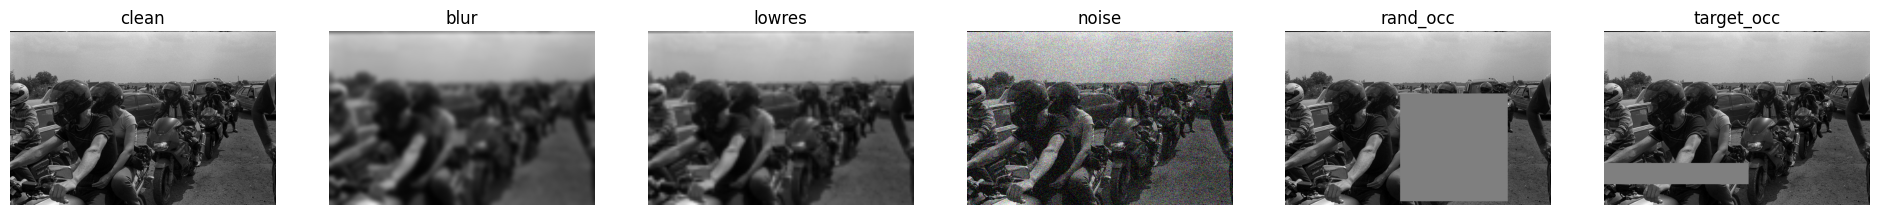

In [6]:
CONDS = ["clean", "blur", "lowres", "noise", "rand_occ", "target_occ"]
GRAY = (127, 127, 127)

def corrupt(img, box, cond, rng):
    W, H = img.size
    if cond == "clean": return img
    if cond == "blur":  return img.filter(ImageFilter.GaussianBlur(5))
    if cond == "lowres":
        small = img.resize((max(8, int(W*0.2)), max(8, int(H*0.2))), Image.BILINEAR)
        return small.resize((W, H), Image.BILINEAR)
    if cond == "noise":
        arr = np.asarray(img).astype(np.float32) + rng.normal(0, 35, (H, W, 3))
        return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    im = img.copy(); dr = ImageDraw.Draw(im)
    if cond == "rand_occ":
        s = int((0.25 * W * H) ** 0.5)
        x = int(rng.integers(0, max(1, W - s))); y = int(rng.integers(0, max(1, H - s)))
        dr.rectangle([x, y, x + s, y + s], fill=GRAY); return im
    if cond == "target_occ":
        x1, y1, x2, y2 = box; mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        r = [(x1, y1, mx, y2), (mx, y1, x2, y2), (x1, y1, x2, my), (x1, my, x2, y2)][int(rng.integers(0, 4))]
        dr.rectangle(r, fill=GRAY); return im

def get_img(d, i, c):
    return corrupt(d["img"], d["box"], c, np.random.default_rng(1000 * i + CONDS.index(c)))

fig, axs = plt.subplots(1, 6, figsize=(24, 4))
for ax, c in zip(axs, CONDS):
    ax.imshow(get_img(test[0], 0, c)); ax.set_title(c); ax.axis("off")
plt.show()

In [7]:
def run_base(data, name, K=4):
    path = f"{SAVE_DIR}/base_{name}.jsonl"; done = set()
    if os.path.exists(path):
        for l in open(path):
            r = json.loads(l); done.add((r["idx"], r["cond"]))
    f = open(path, "a")
    for i, d in enumerate(tqdm(data, desc=name)):
        for c in CONDS:
            if (i, c) in done: continue
            im = get_img(d, i, c)
            g = ground_greedy(im, d["expr"]); s = ground_samples(im, d["expr"], K)
            ious = [iou(b, g["pred"]) if g["pred"] else 0.0 for b in s]
            rec = dict(idx=i, cond=c, expr=d["expr"], gt=d["box"], **g, samples=s,
                       iou=iou(g["pred"], d["box"]),
                       cons_mean=float(np.mean(ious)), agree=float(np.mean([x > 0.5 for x in ious])))
            f.write(json.dumps(rec) + "\n"); f.flush()
    f.close()

In [8]:
run_base(dev, "dev")

dev:   0%|          | 0/100 [00:00<?, ?it/s]

In [9]:
run_base(test, "test")

test:   0%|          | 0/150 [00:00<?, ?it/s]

            Acc50   mIoU  H_digit  consistency
cond                                          
clean       0.920  0.841    1.033        0.893
blur        0.753  0.660    1.371        0.731
lowres      0.813  0.753    1.199        0.816
noise       0.880  0.781    1.160        0.827
rand_occ    0.627  0.592    1.049        0.796
target_occ  0.133  0.379    1.075        0.774
    signal  AUROC     lo     hi
0     u_Hd  0.543  0.497  0.589
1   u_Hmax  0.452  0.412  0.499
2    u_nlp  0.496  0.448  0.542
3   u_minp  0.432  0.389  0.482
4   u_cons  0.715  0.683  0.753
5  u_agree  0.701  0.669  0.734
6   u_free  0.634  0.590  0.678
7  u_combo  0.779  0.747  0.811
             u_Hd  u_Hmax  u_nlp  u_minp  u_cons  u_agree  u_free  u_combo
clean       0.717   0.415  0.625   0.384   0.839    0.788   0.766    0.877
blur        0.719   0.696  0.688   0.655   0.807    0.749   0.710    0.794
lowres      0.776   0.663  0.736   0.651   0.866    0.844   0.679    0.856
noise       0.660   0.609  0.636   0

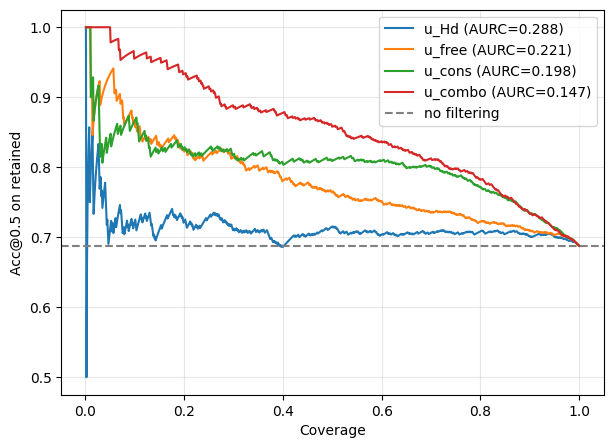

In [10]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def load_df(name):
    df = pd.DataFrame([json.loads(l) for l in open(f"{SAVE_DIR}/base_{name}.jsonl")])
    df["fail"] = (df.iou < 0.5).astype(int)
    df["u_Hd"], df["u_Hmax"], df["u_nlp"], df["u_minp"] = df.H_dmean, df.H_dmax, df.nlp_d, df.minp_d
    df["u_cons"], df["u_agree"] = 1 - df.cons_mean, 1 - df.agree
    return df

dfd, dft = load_df("dev"), load_df("test")
SIGNALS = ["u_Hd", "u_Hmax", "u_nlp", "u_minp", "u_cons", "u_agree"]
FREE = ["u_Hd", "u_Hmax", "u_nlp", "u_minp"]

dfd = dfd.copy()
clf_all  = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(dfd[SIGNALS], dfd.fail)
clf_free = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(dfd[FREE], dfd.fail)
dft["u_combo"] = clf_all.predict_proba(dft[SIGNALS])[:, 1]
dft["u_free"]  = clf_free.predict_proba(dft[FREE])[:, 1]
ALL = SIGNALS + ["u_free", "u_combo"]

def cluster_boot(df, fn, B=500, seed=0):
    rng = np.random.default_rng(seed); g = {k: x for k, x in df.groupby("idx")}; keys = np.array(list(g))
    vals = [fn(pd.concat([g[k] for k in rng.choice(keys, len(keys))])) for _ in range(B)]
    return np.nanpercentile(vals, [2.5, 97.5])

def safe_auc(d, s): return roc_auc_score(d.fail, d[s]) if d.fail.nunique() > 1 else np.nan

tab1 = dft.groupby("cond").agg(Acc50=("fail", lambda x: 1 - x.mean()), mIoU=("iou", "mean"),
        H_digit=("u_Hd", "mean"), consistency=("cons_mean", "mean")).loc[CONDS]
print(tab1.round(3)); tab1.to_csv(f"{SAVE_DIR}/table_rq1_corruption.csv")

rows = []
for s in ALL:
    lo, hi = cluster_boot(dft, lambda d: safe_auc(d, s))
    rows.append(dict(signal=s, AUROC=safe_auc(dft, s), lo=lo, hi=hi))
tab2 = pd.DataFrame(rows); print(tab2.round(3)); tab2.to_csv(f"{SAVE_DIR}/table_rq2_auroc.csv")

tab2b = pd.DataFrame({s: {c: safe_auc(dft[dft.cond == c], s) for c in CONDS} for s in ALL})
print(tab2b.round(3)); tab2b.to_csv(f"{SAVE_DIR}/table_rq2_auroc_per_cond.csv")

def risk_cov(df, s):
    d = df.sort_values(s); acc = 1 - d.fail.values
    return np.arange(1, len(d) + 1) / len(d), np.cumsum(acc) / np.arange(1, len(d) + 1)
plt.figure(figsize=(7, 5))
for s in ["u_Hd", "u_free", "u_cons", "u_combo"]:
    cov, a = risk_cov(dft, s); plt.plot(cov, a, label=f"{s} (AURC={np.mean(1-a):.3f})")
plt.axhline(1 - dft.fail.mean(), ls="--", c="gray", label="no filtering")
plt.xlabel("Coverage"); plt.ylabel("Acc@0.5 on retained"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{SAVE_DIR}/fig_risk_coverage.png", dpi=200, bbox_inches="tight"); plt.show()

In [11]:
YES = [tok.encode(s, add_special_tokens=False)[0] for s in ["Yes", "yes", " Yes"]]
NO  = [tok.encode(s, add_special_tokens=False)[0] for s in ["No", "no", " No"]]

def draw_box(img, b, w=4):
    im = img.copy(); ImageDraw.Draw(im).rectangle(b, outline=(255, 0, 0), width=w); return im

def crop_ctx(img, b, pad=0.15):
    pw, ph = (b[2]-b[0]) * pad, (b[3]-b[1]) * pad
    c = img.crop((int(max(0, b[0]-pw)), int(max(0, b[1]-ph)), int(min(img.width, b[2]+pw)), int(min(img.height, b[3]+ph))))
    s = max(1.0, 336 / min(c.size)); return c.resize((int(c.width*s), int(c.height*s)), Image.BICUBIC)

@torch.no_grad()
def verify_score(img, expr, b, mode="mark"):
    if mode == "mark":
        im = draw_box(img, b); q = f'The red rectangle marks a region of the image. Does the red rectangle tightly and correctly enclose "{expr}"? Answer Yes or No.'
    else:
        im = crop_ctx(img, b); q = f'Is "{expr}" the main object shown in this image? Answer Yes or No.'
    lg = model(**build_inputs(im, q)).logits[0, -1].float()
    return float(torch.sigmoid(torch.logsumexp(lg[YES], 0) - torch.logsumexp(lg[NO], 0)))

def zoom_ground(img, expr, b, ctx=2.0, min_side=448):
    cx, cy = (b[0]+b[2])/2, (b[1]+b[3])/2
    hw, hh = max((b[2]-b[0])*(1+ctx)/2, 96), max((b[3]-b[1])*(1+ctx)/2, 96)
    x1, y1 = int(max(0, cx-hw)), int(max(0, cy-hh)); x2, y2 = int(min(img.width, cx+hw)), int(min(img.height, cy+hh))
    crop = img.crop((x1, y1, x2, y2)); s = max(1.0, min_side / min(crop.size))
    crop2 = crop.resize((int(crop.width*s), int(crop.height*s)), Image.BICUBIC)
    p = ground_greedy(crop2, expr)["pred"]
    if p is None: return None
    fx, fy = crop.width / crop2.width, crop.height / crop2.height
    return [x1 + p[0]*fx, y1 + p[1]*fy, x1 + p[2]*fx, y1 + p[3]*fy]

def dedupe(boxes, thr=0.85):
    out = []
    for b in boxes:
        if b is not None and all(iou(b, o) < thr for o in out): out.append(b)
    return out

def verify_loop(img, expr, rec, sources=("samples", "zoom"), rounds=1, vmode="mark", K=4):
    cands = [rec["pred"]]; gen_calls = 0; cache = {}
    if "samples" in sources: cands += rec["samples"]; gen_calls += K
    def score(b):
        k = tuple(int(round(v)) for v in b)
        if k not in cache: cache[k] = verify_score(img, expr, b, vmode)
        return cache[k]
    best = None
    for _ in range(rounds):
        if "zoom" in sources:
            ref = best if best is not None else next((b for b in cands if b is not None), None)
            if ref is not None:
                zb = zoom_ground(img, expr, ref); gen_calls += 1
                if zb is not None: cands.append(zb)
        cs = dedupe(cands)
        if not cs: break
        new_best = cs[int(np.argmax([score(b) for b in cs]))]
        if best is not None and iou(new_best, best) > 0.95: best = new_best; break
        best = new_best
    return dict(best=best, gen_calls=gen_calls, ver_calls=len(cache))

def run_verify(data, base_name, cfg, tag, sel=None):
    base = [json.loads(l) for l in open(f"{SAVE_DIR}/base_{base_name}.jsonl")]
    path = f"{SAVE_DIR}/ver_{base_name}_{tag}.jsonl"; done = set()
    if os.path.exists(path):
        for l in open(path):
            r = json.loads(l); done.add((r["idx"], r["cond"]))
    f = open(path, "a")
    for r in tqdm(base, desc=tag):
        key = (r["idx"], r["cond"])
        if key in done or (sel is not None and key not in sel): continue
        img = get_img(data[r["idx"]], r["idx"], r["cond"])
        v = verify_loop(img, r["expr"], r, **cfg)
        f.write(json.dumps(dict(idx=r["idx"], cond=r["cond"], v_pred=v["best"], v_iou=iou(v["best"], r["gt"]),
                                cost=v["gen_calls"] + v["ver_calls"])) + "\n"); f.flush()
    f.close()

In [13]:
hard = dfd[dfd.u_Hd > dfd.u_Hd.median()].sample(n=min(100, (dfd.u_Hd > dfd.u_Hd.median()).sum()), random_state=0)
SEL = set(zip(hard.idx, hard.cond))

CFGS = {
  "A_samples":      dict(sources=("samples",),        rounds=1, vmode="mark"),
  "B_zoom":         dict(sources=("zoom",),           rounds=1, vmode="mark"),
  "C_both":         dict(sources=("samples", "zoom"), rounds=1, vmode="mark"),
  "D_both_crop":    dict(sources=("samples", "zoom"), rounds=1, vmode="crop"),
  "E_both_2rounds": dict(sources=("samples", "zoom"), rounds=2, vmode="mark"),
}
for tag, cfg in CFGS.items():
    run_verify(dev, "dev", cfg, tag, sel=SEL)

base_acc = 1 - hard.fail.mean(); rows = []
for tag in CFGS:
    v = pd.DataFrame([json.loads(l) for l in open(f"{SAVE_DIR}/ver_dev_{tag}.jsonl")])
    v = v.merge(hard[["idx", "cond", "fail"]], on=["idx", "cond"])
    acc = (v.v_iou >= 0.5).mean()
    rows.append(dict(cfg=tag, base_acc=base_acc, verified_acc=acc, gain=acc - base_acc, avg_cost=v.cost.mean(),
                     fixed=int(((v.fail == 1) & (v.v_iou >= 0.5)).sum()), broken=int(((v.fail == 0) & (v.v_iou < 0.5)).sum())))
abl = pd.DataFrame(rows); print(abl.round(3)); abl.to_csv(f"{SAVE_DIR}/table_ablation_dev.csv")

A_samples:   0%|          | 0/600 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


B_zoom:   0%|          | 0/600 [00:00<?, ?it/s]

C_both:   0%|          | 0/600 [00:00<?, ?it/s]

D_both_crop:   0%|          | 0/600 [00:00<?, ?it/s]

E_both_2rounds:   0%|          | 0/600 [00:00<?, ?it/s]

              cfg  base_acc  verified_acc  gain  avg_cost  fixed  broken
0       A_samples      0.57          0.52 -0.05      6.87      6      11
1          B_zoom      0.57          0.55 -0.02      2.50      2       4
2          C_both      0.57          0.50 -0.07      8.24      5      12
3     D_both_crop      0.57          0.56 -0.01      8.24      6       7
4  E_both_2rounds      0.57          0.49 -0.08      9.50      4      12


In [14]:
BEST = "C_both"    # Cell 13 ka table dekh kar badlein

In [16]:
run_verify(test, "test", CFGS[BEST], "final")

final:   0%|          | 0/900 [00:00<?, ?it/s]

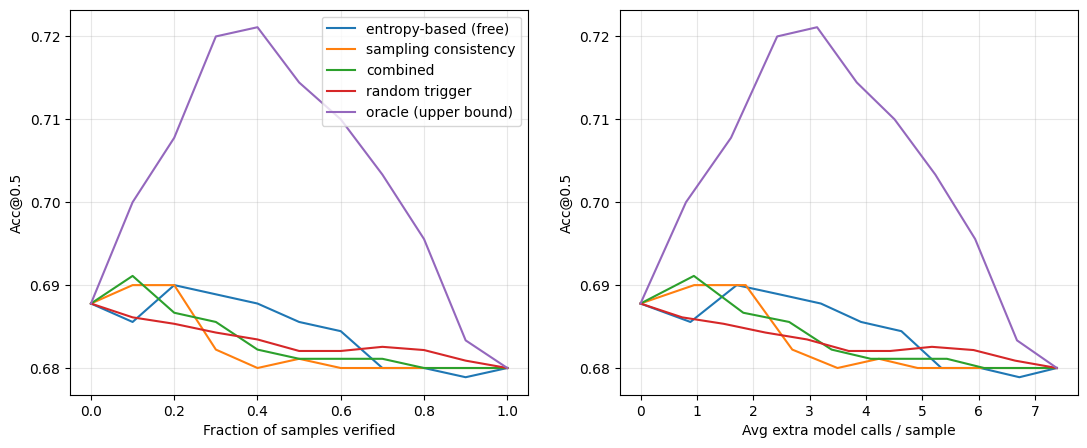

u_free   acc=0.689 (base 0.688)  gain=+0.001 CI[-0.013,+0.014]  cost=2.46 calls/sample
u_cons   acc=0.682 (base 0.688)  gain=-0.006 CI[-0.022,+0.013]  cost=2.69 calls/sample
u_combo  acc=0.686 (base 0.688)  gain=-0.002 CI[-0.019,+0.011]  cost=2.64 calls/sample
random   acc=0.684 (base 0.688)  gain=-0.003 CI[-0.014,+0.007]  cost=2.23 calls/sample
always-verify -> acc: 0.68 fixed: 32 broken: 39
         cond   base  gated_free  always
0       clean  0.920       0.913   0.913
1        blur  0.753       0.767   0.753
2      lowres  0.813       0.840   0.833
3       noise  0.880       0.833   0.807
4    rand_occ  0.627       0.627   0.620
5  target_occ  0.133       0.140   0.153


In [17]:
v = pd.DataFrame([json.loads(l) for l in open(f"{SAVE_DIR}/ver_test_final.jsonl")])
D = dft.merge(v[["idx", "cond", "v_iou", "cost"]], on=["idx", "cond"]).reset_index(drop=True)

def simulate(df, policy, rho, seed=0):
    n = len(df); k = int(round(rho * n)); rng = np.random.default_rng(seed)
    if policy == "random": order = rng.permutation(n)
    elif policy == "oracle": order = np.argsort(-df.fail.values, kind="stable")
    else: order = np.argsort(-df[policy].values, kind="stable")
    trig = np.zeros(n, bool); trig[order[:k]] = True
    final = np.where(trig, df.v_iou.values, df.iou.values)
    return float((final >= 0.5).mean()), float((trig * df.cost.values).sum() / n)

POL = {"u_free": "entropy-based (free)", "u_cons": "sampling consistency", "u_combo": "combined",
       "random": "random trigger", "oracle": "oracle (upper bound)"}
RHOS = np.linspace(0, 1, 11)
fig, axs = plt.subplots(1, 2, figsize=(13, 5)); res = {}
for p, lab in POL.items():
    pts = [np.mean([simulate(D, p, r, s) for s in range(20)], axis=0) if p == "random" else simulate(D, p, r) for r in RHOS]
    res[p] = pts
    axs[0].plot(RHOS, [x[0] for x in pts], label=lab); axs[1].plot([x[1] for x in pts], [x[0] for x in pts], label=lab)
axs[0].set_xlabel("Fraction of samples verified"); axs[1].set_xlabel("Avg extra model calls / sample")
for a in axs: a.set_ylabel("Acc@0.5"); a.grid(alpha=.3)
axs[0].legend(); plt.savefig(f"{SAVE_DIR}/fig_gated_verification.png", dpi=200, bbox_inches="tight"); plt.show()

RHO = 0.3
base = 1 - D.fail.mean()
for p in ["u_free", "u_cons", "u_combo", "random"]:
    gain = lambda d, p=p: simulate(d.reset_index(drop=True), p, RHO)[0] - (1 - d.fail.mean())
    lo, hi = cluster_boot(D, gain, B=300)
    a, c = simulate(D, p, RHO)
    print(f"{p:8s} acc={a:.3f} (base {base:.3f})  gain={a-base:+.3f} CI[{lo:+.3f},{hi:+.3f}]  cost={c:.2f} calls/sample")

fixed  = int(((D.fail == 1) & (D.v_iou >= 0.5)).sum()); broken = int(((D.fail == 0) & (D.v_iou < 0.5)).sum())
print("always-verify -> acc:", (D.v_iou >= 0.5).mean(), "fixed:", fixed, "broken:", broken)

rows = []
for c in CONDS:
    d = D[D.cond == c].reset_index(drop=True)
    rows.append(dict(cond=c, base=1 - d.fail.mean(), gated_free=simulate(d, "u_free", RHO)[0], always=(d.v_iou >= 0.5).mean()))
tab3 = pd.DataFrame(rows); print(tab3.round(3)); tab3.to_csv(f"{SAVE_DIR}/table_rq3_per_condition.csv")

In [18]:
dft_nt = dft[dft.cond != "target_occ"]
print("Acc50 (target_occ ke bina):", round(1 - dft_nt.fail.mean(), 3))

rows = []
for s in ALL:
    lo, hi = cluster_boot(dft_nt, lambda d: safe_auc(d, s))
    rows.append(dict(signal=s, AUROC=safe_auc(dft_nt, s), lo=lo, hi=hi))
tabA = pd.DataFrame(rows)
print(tabA.round(3))
tabA.to_csv(f"{SAVE_DIR}/table_rq2_auroc_no_target_occ.csv")

Acc50 (target_occ ke bina): 0.799
    signal  AUROC     lo     hi
0     u_Hd  0.665  0.600  0.728
1   u_Hmax  0.551  0.491  0.617
2    u_nlp  0.613  0.544  0.678
3   u_minp  0.528  0.463  0.595
4   u_cons  0.824  0.790  0.863
5  u_agree  0.776  0.736  0.816
6   u_free  0.701  0.632  0.767
7  u_combo  0.838  0.805  0.875


In [19]:
def best_cand_iou(r):
    cands = [r["pred"]] + r["samples"]
    return max([iou(b, r["gt"]) for b in cands if b is not None] or [0.0])

bt = [json.loads(l) for l in open(f"{SAVE_DIR}/base_test.jsonl")]
bdf = pd.DataFrame([dict(idx=r["idx"], cond=r["cond"],
                         greedy_ok=r["iou"] >= 0.5,
                         any_candidate_ok=best_cand_iou(r) >= 0.5) for r in bt])

tabB = bdf.groupby("cond")[["greedy_ok", "any_candidate_ok"]].mean().loc[CONDS]
print(tabB.round(3))
print("overall:", bdf[["greedy_ok", "any_candidate_ok"]].mean().round(3).to_dict())
tabB.to_csv(f"{SAVE_DIR}/table_candidate_oracle.csv")

            greedy_ok  any_candidate_ok
cond                                   
clean           0.920             0.967
blur            0.753             0.827
lowres          0.813             0.920
noise           0.880             0.940
rand_occ        0.627             0.720
target_occ      0.133             0.340
overall: {'greedy_ok': 0.688, 'any_candidate_ok': 0.786}


In [20]:
vs = []
for _, r in tqdm(dft.iterrows(), total=len(dft), desc="verifier"):
    if not isinstance(r.pred, list):
        vs.append(np.nan); continue
    img = get_img(test[int(r.idx)], int(r.idx), r.cond)
    vs.append(verify_score(img, r.expr, r.pred, "mark"))
dft["u_verifier"] = 1 - np.array(vs)      # zyada = failure ka shak

dv = dft.dropna(subset=["u_verifier"])
print("pooled AUROC (verifier):", round(safe_auc(dv, "u_verifier"), 3))
tabC = pd.DataFrame({c: {"verifier": safe_auc(dv[dv.cond == c], "u_verifier"),
                         "u_cons":   safe_auc(dv[dv.cond == c], "u_cons")} for c in CONDS}).T
print(tabC.round(3))
tabC.to_csv(f"{SAVE_DIR}/table_verifier_quality.csv")

verifier:   0%|          | 0/900 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


pooled AUROC (verifier): 0.701
            verifier  u_cons
clean          0.541   0.839
blur           0.745   0.807
lowres         0.751   0.866
noise          0.684   0.856
rand_occ       0.780   0.789
target_occ     0.533   0.419
